Regularization and Gradient Descent

Dataset: `california_housing.csv`

Soal 1 (Import data)

- Import library yang diperlukan.
- Baca dataset California Housing.
- Pisahkan fitur (`X`) dan target (`y`).
- Periksa ukuran data, tipe data, nilai kosong, dan statistik dasar.

Target dataset ini adalah `MedHouseVal` (nilai median rumah dalam satuan dataset).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, MinMaxScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score

sns.set_style("whitegrid")

In [21]:
data = pd.read_csv("data/california_housing.csv")

print("Ukuran dataset:", data.shape)
display(data.head())

Ukuran dataset: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print("Kolom:", data.columns.tolist())
print("\nTipe data:")
print(data.dtypes)
print("\nJumlah missing value per kolom:")
print(data.isna().sum())

Kolom: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Tipe data:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Jumlah missing value per kolom:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [4]:
target_col = "MedHouseVal"
if target_col not in data.columns:
    raise ValueError(
        f"Kolom target '{target_col}' tidak ditemukan. "
        f"Kolom yang tersedia: {data.columns.tolist()}"
    )

# Untuk latihan ini gunakan baris dengan nilai lengkap
data = data.dropna().copy()

X = data.drop(columns=[target_col])
y = data[target_col]

print("Jumlah fitur:", X.shape[1])
print("Jumlah baris setelah menghapus missing values:", len(data))
display(data.describe().T)

Jumlah fitur: 8
Jumlah baris setelah menghapus missing values: 20640


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Soal 2 - Train/test split and baseline model

Pisahkan data menjadi training dan testing set. Lalu buat model Linear Regression sederhana dan evaluasi dengan RMSE serta R².

- RMSE yang lebih kecil biasanya lebih baik.
- R² yang lebih dekat ke 1 menunjukkan bahwa model menjelaskan lebih banyak variasi target.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (15480, 8)
Testing set : (5160, 8)


In [6]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_rmse = rmse(y_test, linear_pred)
linear_r2 = r2_score(y_test, linear_pred)

print(f"Linear Regression RMSE: {linear_rmse:.4f}")
print(f"Linear Regression R²  : {linear_r2:.4f}")

Linear Regression RMSE: 0.7356
Linear Regression R²  : 0.5911


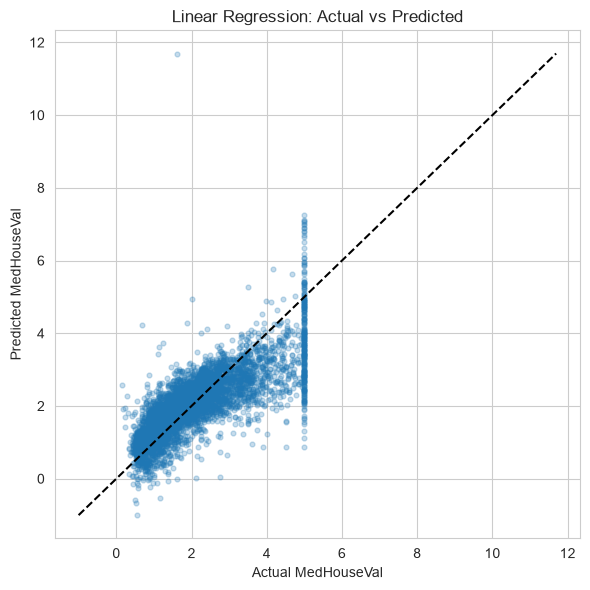

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, linear_pred, alpha=0.25, s=12)
limits = [
    min(y_test.min(), linear_pred.min()),
    max(y_test.max(), linear_pred.max())
]
ax.plot(limits, limits, "k--")
ax.set(
    xlabel="Actual MedHouseVal",
    ylabel="Predicted MedHouseVal",
    title="Linear Regression: Actual vs Predicted"
)
plt.tight_layout()
plt.show()

Soal 3 - Polynomial features

Polynomial features dapat membantu menangkap hubungan non-linear. Agar jumlah fitur tidak membengkak, latihan ini menggunakan satu fitur yang umum dipakai, yaitu `MedInc` (median income).

- Buat fitur polinomial derajat 2.
- Bandingkan Linear Regression biasa dengan Polynomial Regression.
- Perhatikan bahwa model polinomial yang lebih kompleks tidak selalu lebih baik pada data testing.

In [8]:
feature_name = "MedInc"
if feature_name not in X.columns:
    feature_name = X.columns[0]

X_train_one = X_train[[feature_name]]
X_test_one = X_test[[feature_name]]

poly_model = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

poly_model.fit(X_train_one, y_train)
poly_pred = poly_model.predict(X_test_one)

print("Fitur yang digunakan:", feature_name)
print(f"Polynomial Regression (degree=2) RMSE: {rmse(y_test, poly_pred):.4f}")
print(f"Polynomial Regression (degree=2) R²  : {r2_score(y_test, poly_pred):.4f}")

Fitur yang digunakan: MedInc
Polynomial Regression (degree=2) RMSE: 0.8330
Polynomial Regression (degree=2) R²  : 0.4756


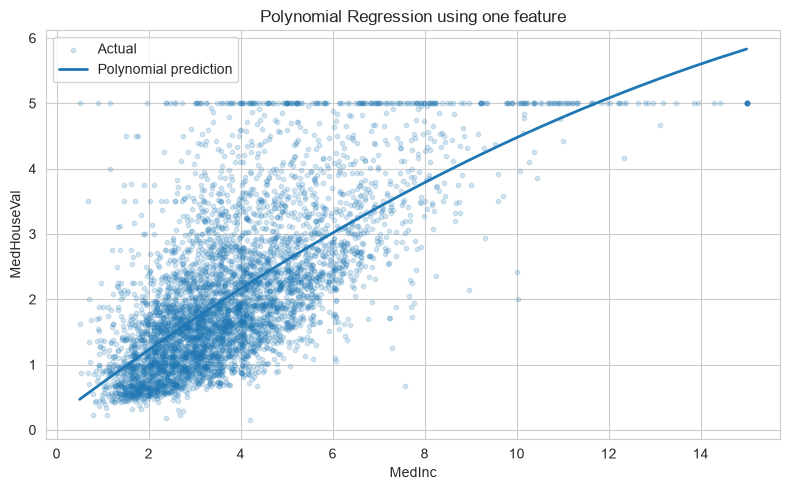

In [9]:
order = np.argsort(X_test_one[feature_name].to_numpy())
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_test_one[feature_name], y_test, alpha=0.18, s=10, label="Actual")
ax.plot(
    X_test_one[feature_name].to_numpy()[order],
    poly_pred[order],
    linewidth=2,
    label="Polynomial prediction"
)
ax.set(
    xlabel=feature_name,
    ylabel="MedHouseVal",
    title="Polynomial Regression using one feature"
)
ax.legend()
plt.tight_layout()
plt.show()

Soal 4 - Ridge Regression (L2 regularization)

Ridge menambahkan penalti L2 pada koefisien. Coba beberapa nilai `alpha` dan pilih yang terbaik melalui cross-validation.

Scaling dilakukan di dalam `Pipeline` agar scaler hanya di-fit pada bagian training setiap fold, sehingga menghindari data leakage.

In [10]:
alphas = np.logspace(-3, 3, 13)

ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RidgeCV(alphas=alphas, cv=5))
])

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)
ridge_estimator = ridge_model.named_steps["model"]

ridge_rmse = rmse(y_test, ridge_pred)
ridge_r2 = r2_score(y_test, ridge_pred)

print("Alpha Ridge terpilih:", ridge_estimator.alpha_)
print(f"Ridge RMSE: {ridge_rmse:.4f}")
print(f"Ridge R²  : {ridge_r2:.4f}")

Alpha Ridge terpilih: 10.0
Ridge RMSE: 0.7354
Ridge R²  : 0.5913


Soal 5 - Lasso Regression (L1 regularization)

Lasso menggunakan penalti L1 dan dapat membuat sebagian koefisien menjadi nol, sehingga bisa membantu seleksi fitur.

- Pilih `alpha` dengan `LassoCV`.
- Hitung berapa koefisien yang tidak nol.
- Bandingkan hasilnya dengan Linear Regression dan Ridge.

In [11]:
lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LassoCV(
        alphas=np.logspace(-4, 1, 15),
        cv=5,
        max_iter=20000,
        random_state=42
    ))
])

lasso_model.fit(X_train, y_train)
lasso_pred = lasso_model.predict(X_test)
lasso_estimator = lasso_model.named_steps["model"]

lasso_rmse = rmse(y_test, lasso_pred)
lasso_r2 = r2_score(y_test, lasso_pred)
nonzero_lasso = np.count_nonzero(lasso_estimator.coef_)

print("Alpha Lasso terpilih:", lasso_estimator.alpha_)
print(f"Lasso RMSE: {lasso_rmse:.4f}")
print(f"Lasso R²  : {lasso_r2:.4f}")
print(f"Koefisien tidak nol: {nonzero_lasso} dari {len(lasso_estimator.coef_)}")

Alpha Lasso terpilih: 0.002682695795279727
Lasso RMSE: 0.7337
Lasso R²  : 0.5932
Koefisien tidak nol: 7 dari 8


Soal 6 - Elastic Net

Elastic Net menggabungkan penalti L1 dan L2. Parameter `l1_ratio` mengatur keseimbangan keduanya:
- Mendekati 1: lebih mirip Lasso.
- Mendekati 0: lebih mirip Ridge.

In [12]:
elastic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", ElasticNetCV(
        alphas=np.logspace(-4, 1, 12),
        l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
        cv=5,
        max_iter=20000,
        random_state=42
    ))
])

elastic_model.fit(X_train, y_train)
elastic_pred = elastic_model.predict(X_test)
elastic_estimator = elastic_model.named_steps["model"]

elastic_rmse = rmse(y_test, elastic_pred)
elastic_r2 = r2_score(y_test, elastic_pred)

print("Alpha Elastic Net terpilih:", elastic_estimator.alpha_)
print("L1 ratio terpilih:", elastic_estimator.l1_ratio_)
print(f"Elastic Net RMSE: {elastic_rmse:.4f}")
print(f"Elastic Net R²  : {elastic_r2:.4f}")

Alpha Elastic Net terpilih: 0.002310129700083158
L1 ratio terpilih: 1.0
Elastic Net RMSE: 0.7339
Elastic Net R²  : 0.5929


Soal 7 - Compare model performance

Bandingkan RMSE dan R² pada testing set. Hasil aktual bergantung pada isi dataset dan versi library yang digunakan.

In [13]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge", "Lasso", "Elastic Net"],
    "RMSE": [linear_rmse, ridge_rmse, lasso_rmse, elastic_rmse],
    "R2": [linear_r2, ridge_r2, lasso_r2, elastic_r2]
}).sort_values("RMSE")

display(results.reset_index(drop=True))

,Model,RMSE,R2
0,Lasso,0.733708,0.593168
1,Elastic Net,0.733937,0.592914
2,Ridge,0.735409,0.591279
3,Linear Regression,0.735615,0.591051


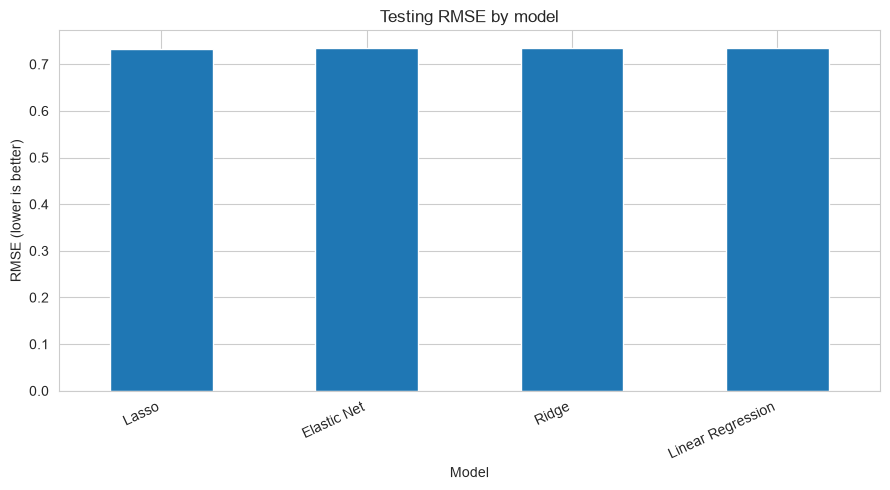

In [14]:
ax = results.sort_values("RMSE").plot(
    x="Model", y="RMSE", kind="bar", legend=False, figsize=(9, 5)
)
ax.set_ylabel("RMSE (lower is better)")
ax.set_title("Testing RMSE by model")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

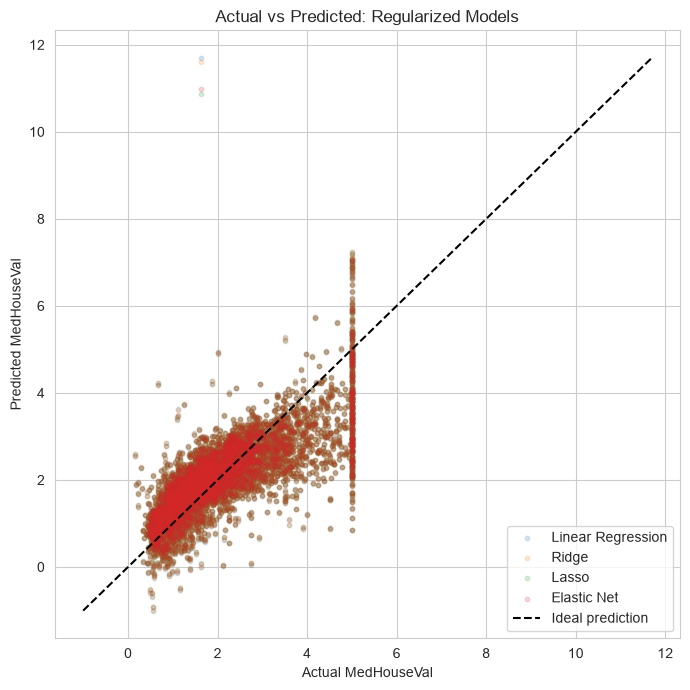

In [15]:
predictions = {
    "Linear Regression": linear_pred,
    "Ridge": ridge_pred,
    "Lasso": lasso_pred,
    "Elastic Net": elastic_pred
}

fig, ax = plt.subplots(figsize=(7, 7))
for name, pred in predictions.items():
    ax.scatter(y_test, pred, alpha=0.18, s=10, label=name)

limits = [
    min(y_test.min(), min(pred.min() for pred in predictions.values())),
    max(y_test.max(), max(pred.max() for pred in predictions.values()))
]
ax.plot(limits, limits, "k--", label="Ideal prediction")
ax.set(
    xlabel="Actual MedHouseVal",
    ylabel="Predicted MedHouseVal",
    title="Actual vs Predicted: Regularized Models"
)
ax.legend()
plt.tight_layout()
plt.show()

Soal 8 - Inspect coefficients

Bandingkan koefisien dari model Linear Regression, Ridge, Lasso, dan Elastic Net. Model-model ini menggunakan fitur yang sudah distandardisasi, sehingga besar koefisien lebih mudah dibandingkan.

In [16]:
coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Linear": linear_model.named_steps["model"].coef_,
    "Ridge": ridge_model.named_steps["model"].coef_,
    "Lasso": lasso_model.named_steps["model"].coef_,
    "ElasticNet": elastic_model.named_steps["model"].coef_
}).set_index("Feature")

display(coef_table)

,Linear,Ridge,Lasso,ElasticNet
Feature,,,,
MedInc,0.852108,0.851446,0.837713,0.839744
HouseAge,0.120655,0.121473,0.122236,0.122095
AveRooms,-0.302106,-0.299816,-0.265839,-0.270897
AveBedrms,0.348606,0.345789,0.312069,0.317176
Population,-0.001645,-0.001376,-0.000000,-0.000000
AveOccup,-0.041164,-0.041202,-0.038483,-0.038874
Latitude,-0.893147,-0.885227,-0.864435,-0.868309
Longitude,-0.867840,-0.859804,-0.837195,-0.841359


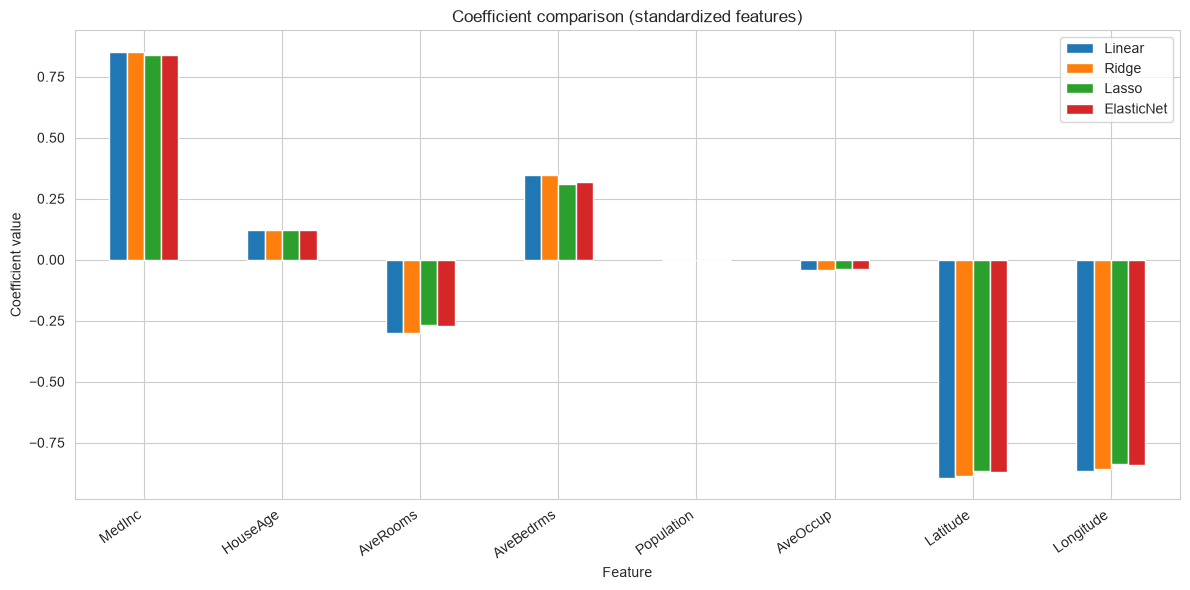

In [17]:
coef_table.plot(kind="bar", figsize=(12, 6))
plt.title("Coefficient comparison (standardized features)")
plt.ylabel("Coefficient value")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Soal 9 - Stochastic Gradient Descent (SGD)

SGD sensitif terhadap skala fitur. Pertama, coba SGD dengan fitur asli. Setelah itu, gunakan `StandardScaler` dan bandingkan RMSE.

SGD dapat menghasilkan hasil yang berbeda dari model closed-form karena optimisasi dilakukan secara iteratif.

In [18]:
sgd_unscaled = SGDRegressor(
    max_iter=2000,
    tol=1e-3,
    random_state=42,
    learning_rate="invscaling",
    eta0=0.001
)
sgd_unscaled.fit(X_train, y_train)
sgd_unscaled_pred = sgd_unscaled.predict(X_test)

print(f"SGD tanpa scaling RMSE: {rmse(y_test, sgd_unscaled_pred):.4f}")

SGD tanpa scaling RMSE: 18064519358316.8594


In [19]:
sgd_scaled_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SGDRegressor(
        max_iter=5000,
        tol=1e-4,
        random_state=42,
        learning_rate="adaptive",
        eta0=0.01,
        penalty="l2"
    ))
])

sgd_scaled_model.fit(X_train, y_train)
sgd_scaled_pred = sgd_scaled_model.predict(X_test)

print(f"SGD dengan scaling RMSE: {rmse(y_test, sgd_scaled_pred):.4f}")
print(f"SGD dengan scaling R²  : {r2_score(y_test, sgd_scaled_pred):.4f}")

SGD dengan scaling RMSE: 76958466.8132
SGD dengan scaling R²  : -4475910352381104.0000


In [20]:
sgd_results = pd.DataFrame({
    "Model": ["SGD tanpa scaling", "SGD dengan StandardScaler"],
    "RMSE": [
        rmse(y_test, sgd_unscaled_pred),
        rmse(y_test, sgd_scaled_pred)
    ],
    "R2": [
        r2_score(y_test, sgd_unscaled_pred),
        r2_score(y_test, sgd_scaled_pred)
    ]
})
display(sgd_results)

,Model,RMSE,R2
0,SGD tanpa scaling,1.806452e+13,-2.466161e+26
1,SGD dengan StandardScaler,7.695847e+07,-4.475910e+15


Sumber Dataset

Mendeley Data - California Housing Dataset

Simpan file sebagai `data/california_housing.csv` sebelum menjalankan notebook.